# Homework #4

## Regularization in Machine Learning

This colaboratory contains Homework #4 of the Machine Learning course, which is due **November 01, midnight (23:59 Estonian time)**. To complete the homework, extract **(File -> Download .ipynb)** and submit to the course webpage.


## Submission's rules:

1.   Please, submit only .ipynb that you extract from the Colaboratory.
2. Run your homework exercises before submitting (output should be present, preferably restart the kernel and press run all the cells).
3. Do not change the description of tasks in red (even if there is a typo|mistake|etc.).
4. Please, make sure to avoid unnecessary long printouts.
5. Each task should be solved right under the question of the task and not elsewhere.
6. Solutions to both regular and bonus exercises should be submitted in one IPYNB file.

## Note on AI usage

We know that most of you use AI for homework, and that is ok. We also know that many students struggle to use it to enhance their learning, beyond getting a quick solution and hoping it works. We want to help you make the most of this course. That is why we have already introduced in-person paper summary discussions and emphasised personal interaction during lectures and practice sessions. However, homeworks remain a large and important part of the course, so we also want to help you learn more from those assignments.

For your next homework exercise, try this:

- Attempt it yourself first. Write down your approach, even if it’s incomplete or you expect mistakes.
- Identify where you are stuck. What is preventing you from completing the task?
- Ask for targeted help. Request a hint, explanation, or debugging suggestion, then try applying it yourself.
- Reattempt independently. Change a parameter or part of the setup, predict what should happen, and check whether the results match your expectations.


When prompting your AI assistant, try asking for guidance instead of ready-made answer:
> Help me learn while working on this assignment. First ask about my attempt, then give one hint or question at a time and wait for my response. If I’m missing a concept, explain it using a small example. Finish by checking whether I can apply the idea independently.

##List of Homework's exercises:

1.   [Ex1](#scrollTo=j5oTPhWPwHuP) - 4 points
2.   [Ex2](#scrollTo=Gqw_WFbk4izQ) - 6 points
3.   [Bonus 1](#scrollTo=jdZkblZW7bEp) - up to 4 points (based on quality of presentation)


## Homework exercise 1: Impact of Feature Selection and Regularisation on Logistic Regression Models (4 points)

<font color='red'>  In this exercise, you will explore how feature selection and regularisation affect the performance of logistic regression models. You will apply Lasso (L1 regularisation) for feature selection, train classification models with different settings, and evaluate their performance to identify signs of overfitting, underfitting, or achieving a good fit.  </font>

In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge, Lasso, LogisticRegression
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer

<font color='red'> Here we will work with a new dataset called **SpeedDating**. This data was gathered from participants in experimental speed dating events from 2002-2004. During the events, the attendees would have a four-minute "first date" with every other participant of the opposite sex. At the end of their four minutes, participants were asked if they would like to see their date again. They were also asked to rate their date on six attributes: Attractiveness, Sincerity, Intelligence, Fun, Ambition, and Shared Interests. The dataset also includes questionnaire data gathered from participants at different points in the process. These fields include: demographics, dating habits, self-perception across key attributes, beliefs on what others find valuable in a mate, and lifestyle information.
You can find more detailed information on the attributes of this dataset via the link: https://www.openml.org/search?type=data&sort=nr_of_likes&status=active&id=40536.


In [2]:
# Fetching the dataset SpeedDating from OPENML library
dating = fetch_openml(data_id=40536)

In [3]:
dating.frame.info()

<class 'pandas.DataFrame'>
RangeIndex: 8378 entries, 0 to 8377
Columns: 121 entries, has_null to match
dtypes: category(62), float64(57), int64(2)
memory usage: 4.3 MB


In [4]:
dating.data

,has_null,wave,gender,age,age_o,d_age,d_d_age,race,race_o,samerace,...,expected_num_interested_in_me,expected_num_matches,d_expected_happy_with_sd_people,d_expected_num_interested_in_me,d_expected_num_matches,like,guess_prob_liked,d_like,d_guess_prob_liked,met
0,0,1,female,21.0,27.0,6,[4-6],Asian/Pacific Islander/Asian-American,European/Caucasian-American,0,...,2.0,4.0,[0-4],[0-3],[3-5],7.0,6.0,[6-8],[5-6],0.0
1,0,1,female,21.0,22.0,1,[0-1],Asian/Pacific Islander/Asian-American,European/Caucasian-American,0,...,2.0,4.0,[0-4],[0-3],[3-5],7.0,5.0,[6-8],[5-6],1.0
2,1,1,female,21.0,22.0,1,[0-1],Asian/Pacific Islander/Asian-American,Asian/Pacific Islander/Asian-American,1,...,2.0,4.0,[0-4],[0-3],[3-5],7.0,NaN,[6-8],[0-4],1.0
3,0,1,female,21.0,23.0,2,[2-3],Asian/Pacific Islander/Asian-American,European/Caucasian-American,0,...,2.0,4.0,[0-4],[0-3],[3-5],7.0,6.0,[6-8],[5-6],0.0
4,0,1,female,21.0,24.0,3,[2-3],Asian/Pacific Islander/Asian-American,Latino/Hispanic American,0,...,2.0,4.0,[0-4],[0-3],[3-5],6.0,6.0,[6-8],[5-6],0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8373,1,21,male,25.0,26.0,1,[0-1],European/Caucasian-American,Latino/Hispanic American,0,...,NaN,3.0,[7-10],[0-3],[3-5],2.0,5.0,[0-5],[5-6],0.0
8374,1,21,male,25.0,24.0,1,[0-1],European/Caucasian-American,Other,0,...,NaN,3.0,[7-10],[0-3],[3-5],4.0,4.0,[0-5],[0-4],0.0
8375,1,21,male,25.0,29.0,4,[4-6],European/Caucasian-American,Latino/Hispanic American,0,...,NaN,3.0,[7-10],[0-3],[3-5],6.0,5.0,[6-8],[5-6],0.0
8376,1,21,male,25.0,22.0,3,[2-3],European/Caucasian-American,Asian/Pacific Islander/Asian-American,0,...,NaN,3.0,[7-10],[0-3],[3-5],5.0,5.0,[0-5],[5-6],0.0


<font color='red'> We are trying to predict if it was a match (yes/no).

In [5]:
dating.target #labels

0       0
1       0
2       1
3       1
4       1
       ..
8373    0
8374    0
8375    0
8376    0
8377    0
Name: match, Length: 8378, dtype: category
Categories (2, str): ['0', '1']

<font color='red'> **(Homework exercise 1- a)** To prepare the data for training, you need to complete several prepropressing steps: balance the dataset (use [`SMOTE`](https://imbalanced-learn.org/stable/over_sampling.html#)), handle numerical and categorical features (use `OneHotEncoder()` for categorical features and `StandardScaler()` for numerical), impute the missing values (use [`sklearn Simple Imputer`](https://scikit-learn.org/1.5/modules/impute.html )) and split into training and test sets. It is super important that you do these operations in the right order. </font>

<font color='red'> We propose that you first split train and test, then impute missing data (feel free to use `mean` imputation strategy for numeric values and `most_frequent` for categorical). Next, you can balance your training data using SMOTENC (SMOTE for Numeric and Categorical data). Finally, you should perform one-hot encoding on categorical variables and do the scaling of numeric features both in train and test sets.

After doing all that, please answer the question below. **(1.5 points)** </font>


In [6]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.over_sampling import SMOTENC

#### YOUR CODE STARTS ####
import warnings
warnings.filterwarnings('ignore')

X = dating.data.copy()
y = dating.target.astype(int)  # 1 = match, 0 = no match

cat_cols = X.select_dtypes(exclude='number').columns.tolist()
num_cols = X.select_dtypes(include='number').columns.tolist()
X[cat_cols] = X[cat_cols].astype(object)  # plain python objects instead of pandas categories (needed by the imputer / SMOTENC)
print(f'{len(num_cols)} numeric and {len(cat_cols)} categorical features')
print('Class balance in the full data:', y.value_counts().to_dict())

# 1) split first, so that nothing from the test set is used in any of the next steps
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# 2) impute missing values, imputers are fitted on the training set only
num_imputer = SimpleImputer(strategy='mean')
cat_imputer = SimpleImputer(strategy='most_frequent')

def impute(df, fit=False):
    num = num_imputer.fit_transform(df[num_cols]) if fit else num_imputer.transform(df[num_cols])
    cat = cat_imputer.fit_transform(df[cat_cols]) if fit else cat_imputer.transform(df[cat_cols])
    return pd.concat([pd.DataFrame(num, columns=num_cols, index=df.index),
                      pd.DataFrame(cat, columns=cat_cols, index=df.index)], axis=1)

X_train_imp = impute(X_train, fit=True)
X_test_imp = impute(X_test)

# 3) balance ONLY the training set with SMOTENC (SMOTE for numeric + categorical data)
smote = SMOTENC(categorical_features=[X_train_imp.columns.get_loc(c) for c in cat_cols], random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_imp, y_train)
print('Training set before SMOTENC:', y_train.value_counts().to_dict(), '-> after:', y_train_bal.value_counts().to_dict())

# 4) one-hot encode categorical and scale numeric features (fitted on the training set, applied to both)
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
])
X_train_prep = preprocessor.fit_transform(X_train_bal)
X_test_prep = preprocessor.transform(X_test_imp)
feature_names = preprocessor.get_feature_names_out()

print('Final shapes - train:', X_train_prep.shape, 'test:', X_test_prep.shape)
#### YOUR CODE ENDS ####

59 numeric and 61 categorical features
Class balance in the full data: {0: 6998, 1: 1380}


Training set before SMOTENC: {0: 5598, 1: 1104} -> after: {0: 5598, 1: 5598}


Final shapes - train: (11196, 500) test: (1676, 500)


<font color='red'>**Question:** Suppose someone changes the order of preprocessing steps.
Give two examples of incorrect orderings (e.g. doing SMOTE before splitting, scaling before imputing, etc.) and explain why each would lead to unreliable results.</font>

**Answer:**

1. **SMOTE (oversampling) before the train/test split.** SMOTE creates synthetic minority samples by interpolating between real neighbours. If it is applied to the whole dataset, synthetic points made from test samples end up in the training set (and synthetic points made from training samples end up in the test set). The model is then evaluated on data that is almost a copy of what it was trained on (*data leakage*), and the test set no longer has the real class distribution (≈16% matches) but an artificial 50/50 one. The test score becomes over-optimistic and does not show how the model works on real, unseen dates.

2. **Imputation or scaling fitted on the whole dataset before splitting** (e.g. `StandardScaler().fit(X)` or mean imputation on all rows). The means / standard deviations would then be computed using test rows, so information about the test set leaks into training, again making the evaluation optimistic. A related wrong order is **scaling before imputing**: `StandardScaler` cannot work with `NaN`, and if the missing values are filled with the raw-scale mean *after* scaling, they get values that make no sense on the standardised scale (e.g. 25 years instead of ~0), which distorts the feature. Similarly, **one-hot encoding before SMOTE** would make SMOTE treat the 0/1 dummy columns as numbers and interpolate them, producing impossible values like "0.37 of a field of study".


<font color='red'> **(Homework exercise 1- b)** Perform feature selection using Lasso and print the names of the selected features.

TIPS: Because we work with classification, you cannot use LinearRegression with L1 regularisation, instead you can use LogisticRegression with L1. You can select the regularization parameter (in LogisticRegression called `C_value`) by trial-and error and see when the results seem reasonable, you don't have to do cross-validation here.
**(1 point)**</font>

In [7]:
#### YOUR CODE STARTS ####
# L1-regularised logistic regression; smaller C = stronger regularisation = fewer non-zero weights.
# Trial and error on C: 0.005 -> 23 features, 0.01 -> 50, 0.02 -> 81, 0.05 -> 119, 0.1 -> 161 (out of 500).
# C = 0.01 keeps ~10% of the features while the test accuracy stays close to the model with all features.
C_value = 0.01
lasso_logreg = LogisticRegression(penalty='l1', solver='liblinear', C=C_value, random_state=42)
lasso_logreg.fit(X_train_prep, y_train_bal)

selected = np.flatnonzero(lasso_logreg.coef_[0])
selected_features = feature_names[selected]
print(f'C = {C_value}: {len(selected)} of {len(feature_names)} features selected')
print(', '.join(name.split('__', 1)[1] for name in selected_features))
#### YOUR CODE ENDS ####

C = 0.01: 50 of 500 features selected
d_age, pref_o_intelligence, pref_o_ambitious, attractive_o, funny_o, ambitous_o, shared_interests_o, sincere_important, ambtition_important, attractive, intelligence, attractive_partner, funny_partner, ambition_partner, sports, exercise, shopping, expected_num_matches, like, guess_prob_liked, met, d_d_age_[7-37], race_o_European/Caucasian-American, samerace_1, d_pref_o_funny_[16-20], d_pref_o_shared_interests_[16-20], d_attractive_o_[0-5], d_attractive_o_[6-8], d_sinsere_o_[6-8], d_intelligence_o_[6-8], d_funny_o_[0-5], d_ambitous_o_[6-8], d_shared_interests_o_[0-5], d_shared_interests_o_[6-8], d_sincere_[6-8], d_intelligence_[9-10], d_funny_[9-10], d_attractive_partner_[0-5], d_attractive_partner_[6-8], d_funny_partner_[0-5], d_ambition_partner_[6-8], d_shared_interests_partner_[0-5], d_exercise_[9-10], d_movies_[9-10], d_expected_happy_with_sd_people_[5-6], d_expected_num_matches_[0-2], d_like_[0-5], d_like_[6-8], d_guess_prob_liked_[0-4], d_gues

<font color='red'> **(Homework exercise 1- c)** We want to understand if/how feature selection might have affected the results of the classification model. For this let's train four logistic regression models with and without extra regularisation. This time, unlike regularisation in the previous exercise, L2 is meant to reduce overfitting, not to help select features.

1.   Train on **all** features **without** L2 regularisation
2.   Train on **all** features **with** L2 regularisation
3.   Train on **selected** features (from your Lasso feature selection) **without** L2 regularisation
4.   Train on **selected** features (from your Lasso feature selection) **with** L2 regularisation  
<font color='red'>**(1 point)**</font>

In [8]:
# Model1: train on all features without L2 regularisation
#### YOUR CODE STARTS ####
L2_C = 0.01  # strength of the L2 regularisation used in models 2 and 4 (C = 1/lambda)

model_1 = LogisticRegression(penalty=None, max_iter=10000)
model_1.fit(X_train_prep, y_train_bal)
#### YOUR CODE ENDS ####

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",None
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the o

In [9]:
# Model2: train on all features with L2 regularisation
#### YOUR CODE STARTS ####
model_2 = LogisticRegression(penalty='l2', C=L2_C, max_iter=10000)
model_2.fit(X_train_prep, y_train_bal)
#### YOUR CODE ENDS ####

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.01
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the 

In [10]:
# Model3: train on selected features without L2 regularisation
#### YOUR CODE STARTS ####
X_train_sel = X_train_prep[:, selected]
X_test_sel = X_test_prep[:, selected]

model_3 = LogisticRegression(penalty=None, max_iter=10000)
model_3.fit(X_train_sel, y_train_bal)
#### YOUR CODE ENDS ####

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",None
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the o

In [11]:
# Model4: train on selected features with L2 regularisation
#### YOUR CODE STARTS ####
model_4 = LogisticRegression(penalty='l2', C=L2_C, max_iter=10000)
model_4.fit(X_train_sel, y_train_bal)
#### YOUR CODE ENDS ####

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.01
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the 

<font color='red'> **(Homework exercise 1- d)** Concisely report the accuracies on both training and test sets for all four models from **1-c**. Compare the results across all models. **(0.5 points)**

In [12]:
#### YOUR CODE STARTS ####
from sklearn.metrics import accuracy_score, f1_score

runs = {
    'Model1: all features, no L2': (model_1, X_train_prep, X_test_prep),
    'Model2: all features, L2': (model_2, X_train_prep, X_test_prep),
    'Model3: selected features, no L2': (model_3, X_train_sel, X_test_sel),
    'Model4: selected features, L2': (model_4, X_train_sel, X_test_sel),
}
rows = []
for name, (m, Xtr, Xte) in runs.items():
    train_acc = accuracy_score(y_train_bal, m.predict(Xtr))
    test_acc = accuracy_score(y_test, m.predict(Xte))
    rows.append({'model': name, 'features': Xtr.shape[1], 'train accuracy': round(train_acc, 3),
                 'test accuracy': round(test_acc, 3), 'train - test': round(train_acc - test_acc, 3),
                 'test F1 (match)': round(f1_score(y_test, m.predict(Xte)), 3)})
results_ex1 = pd.DataFrame(rows).set_index('model')
print(f'For reference: always predicting "no match" gives test accuracy {1 - y_test.mean():.3f}')
results_ex1
#### YOUR CODE ENDS ####

For reference: always predicting "no match" gives test accuracy 0.835


,features,train accuracy,test accuracy,train - test,test F1 (match)
model,,,,,
"Model1: all features, no L2",500,0.899,0.816,0.083,0.508
"Model2: all features, L2",500,0.871,0.807,0.064,0.548
"Model3: selected features, no L2",50,0.855,0.788,0.066,0.521
"Model4: selected features, L2",50,0.850,0.789,0.061,0.534


<font color='red'> Explain in your words, for each model, whether they exhibit overfitting, underfitting, or a normal fit. Explain your reasoning.

Your answer:

*Note first:* the training set was balanced with SMOTENC (50% matches), but the test set keeps the real distribution (only 16.5% matches). Always predicting "no match" already gives a test accuracy of 0.835, higher than any of the models – so accuracy alone is misleading here, and I also report the F1 score for the "match" class. The models try to find matches, so they make more false-positive predictions on the real (imbalanced) data.

* **Model 1 (all 500 features, no L2): mild overfitting.** It has the highest training accuracy (0.899) but also the largest train–test gap (0.083) and the worst F1 on the test set (0.508). Without any penalty the model can give large weights to hundreds of rare one-hot columns (e.g. 259 study fields) and to the synthetic SMOTE points, i.e. it partly learns noise.
* **Model 2 (all features, L2 with C = 0.01): the best (normal) fit.** L2 shrinks the weights, so the training accuracy drops to 0.871, the gap becomes smaller (0.064), and the F1 on the test set is the best (0.548). The test accuracy is slightly lower than for Model 1 (0.807 vs 0.816), but that is because it predicts "match" more often, which is what we want.
* **Model 3 (50 Lasso-selected features, no L2): slight underfitting.** With only 50 features the model is simpler: the gap is smaller than for Model 1 (0.066), so less overfitting, but both training (0.855) and test accuracy (0.788) are lower than with all features. Lasso with C = 0.01 removed 90% of the features, including some that carried useful information.
* **Model 4 (50 selected features + L2): slight underfitting, almost identical to Model 3** (0.850 / 0.789, gap 0.061). With only 50 features the model is already strongly constrained, so the extra L2 penalty has little to do and changes the results only marginally.

**Overall:** none of the models is severely over- or underfitted (train–test gaps of 6–8 points, part of which is due to the balanced vs. imbalanced class distribution). Regularisation and feature selection both reduce the gap, but aggressive feature selection costs some predictive power. Here L2 on all features gave the best trade-off; feature selection is still useful if we want a small, interpretable model (50 instead of 500 features) at the cost of ~2 points of accuracy.

## Homework exercise 2 (6 points): Traffic signs classification
<font color='red'> In the practice session, we applied data augmentation on CIFAR-10, which was already a balanced dataset. Thus, we are introducing a new, trickier dataset for this task - the Belgium Traffic Sign dataset ([BelgiumTSC](https://btsd.ethz.ch/shareddata/)). Our goal here is to classify the traffic signs.

In [13]:
import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf

import matplotlib.pyplot as plt
import seaborn as sns

import os
from PIL import Image # Python Image processing Library

from keras.layers import Input, Conv2D, Activation, Flatten, Dense, MaxPooling2D, BatchNormalization, Dropout, Normalization
from keras.models import Model
from keras.optimizers import Adam

<font color='red'> Firstly, we load the data from Google Drive.

In [ ]:
# newer gdown versions removed the --fuzzy flag, so fall back to the plain command if it fails
!gdown --fuzzy https://drive.google.com/file/d/1gCq2h-BX0CPHlfbTDEWa0Lzb26ryqQYH/view?usp=sharing || gdown https://drive.google.com/file/d/1gCq2h-BX0CPHlfbTDEWa0Lzb26ryqQYH/view?usp=sharing

In [ ]:
!unzip -q BelgiumTSC.zip -d data/

<font color='red'> The contents of the archive contains 62 folders with .png images of traffic signs and an annotations file with labels and coordinates of signs. We won't use the coordinates as we are interested only in classification.

In [ ]:
!ls data/BelgiumTSC/

In [ ]:
!ls  data/BelgiumTSC/00000

<font color='red'> We can also take a look at a single image.

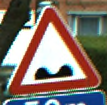

In [18]:
Image.open('./data/BelgiumTSC/00000/01153_00002.png')

In [ ]:
# A path to our dataset
dataset_path = '/content/data/BelgiumTSC/'

In [20]:
# Read a csv file with annotations
annt_df = pd.read_csv(os.path.join(dataset_path, 'annotations.csv'))
annt_df.head()

,Filepath,Width,Height,Roi.x1,Roi.y1,Roi.x2,Roi.y2,ClassId
0,00000/01153_00002.png,105,107,9,9,96,98,0
1,00000/01160_00000.png,94,105,8,9,86,95,0
2,00000/01797_00000.png,85,95,7,8,77,87,0
3,00000/01798_00000.png,81,88,7,7,74,81,0
4,00000/01799_00002.png,99,110,8,9,91,100,0


 <font color='red'> Notice that the images have different widths and heights. We will deal with this issue later.

 <font color='red'> Roi.x1, Roi.y1, Roi.x2, and Roi.y2—represent the coordinates of a bounding box that highlights the most relevant or important part of each image. For this homework we will not use the ROI information because our focus here is on the overall image properties and not on extracting important regions.

 <font color='red'>Before loading any images, let's plot the distribution of images per class.

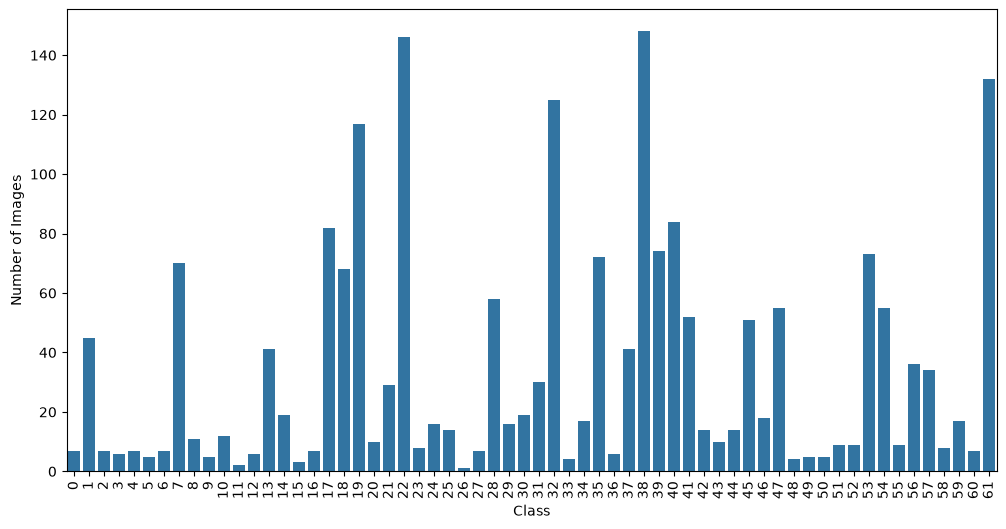

In [21]:
plt.figure(figsize=(12, 6))
sns.countplot(x='ClassId', data=annt_df)
plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.xticks(rotation=90)
plt.show()

<font color='red'> The dataset is heavily unbalanced, with the largest class containing 70 times more images than the smallest one. To make our lives a bit easier, we will remove any classes that have fewer than 8 images.

<font color='red'> **(Homework exercise 2- a)** Drop rows from the DataFrame where the image class has fewer than 8 samples (i.e., images). Then, rename the remaining classes to ensure that the class labels are sequential with no gaps in the numbering. **(1 point)**. </font>

In [22]:
##### YOUR CODE STARTS #####
# a few images are listed twice in annotations.csv - keep each image once, otherwise
# the same picture could end up both in the training and in the test set
annt_df = annt_df.drop_duplicates(subset='Filepath').reset_index(drop=True)

class_counts = annt_df['ClassId'].value_counts()
small_classes = sorted(class_counts[class_counts < 8].index)
print(f'Removing {len(small_classes)} classes with fewer than 8 images: {small_classes}')
annt_df = annt_df[~annt_df['ClassId'].isin(small_classes)].reset_index(drop=True)

# rename the remaining classes to 0, 1, 2, ... (in the order of the original ids)
old_to_new = {old: new for new, old in enumerate(sorted(annt_df['ClassId'].unique()))}
annt_df['ClassId'] = annt_df['ClassId'].map(old_to_new)
num_classes = annt_df['ClassId'].nunique()
print(f'{len(annt_df)} images in {num_classes} classes, labels from {annt_df.ClassId.min()} to {annt_df.ClassId.max()}')
##### YOUR CODE ENDS #####

Removing 19 classes with fewer than 8 images: [0, 2, 3, 4, 5, 6, 9, 11, 12, 15, 16, 26, 27, 33, 36, 48, 49, 50, 60]
1958 images in 43 classes, labels from 0 to 42


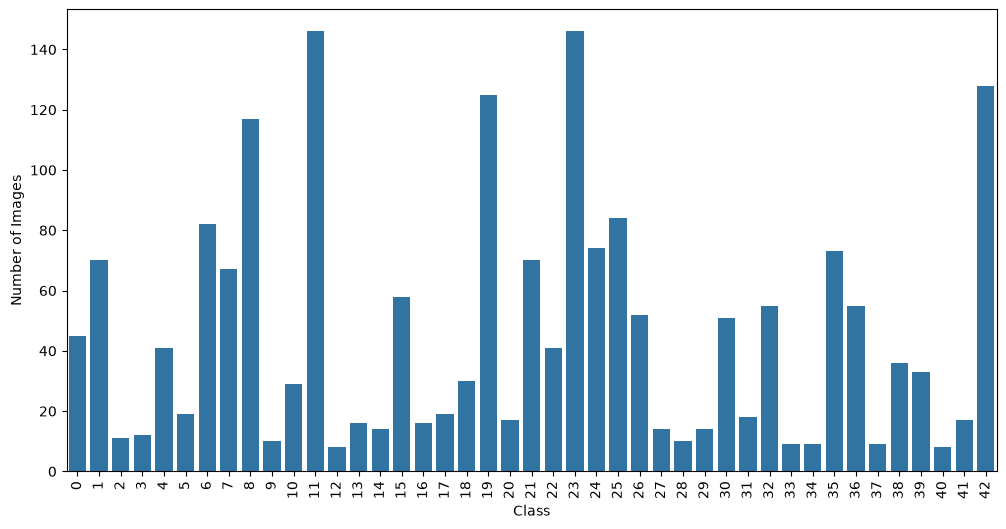

In [23]:
plt.figure(figsize=(12, 6))
sns.countplot(x='ClassId', data=annt_df)
plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.xticks(rotation=90)
plt.show()

<font color='red'>  Explain in your words, why we removed image classes with fewer than 8 samples from the dataset. How this decision may relate to the upcoming split of our dataset into training, validation, and test sets?

Your answer: We need every class to appear in all three sets: in the **training** set so the model can learn it, in the **validation** set so early stopping / model selection also takes it into account, and in the **test** set so we can measure its accuracy. With an 80/10/10 split a class needs at least ~8 images to get at least one image in validation and one in test while still leaving ~6 images for training (8 → 6/1/1). A class with e.g. 2–5 images would either be missing from the validation/test sets (then its accuracy cannot be measured, and stratified splitting even fails), or would leave only 1–3 training images, which is far too little for a CNN to learn anything. Such classes would only add noise to the evaluation: the per-class accuracy would be computed from a single image (0% or 100%).

<font color='red'> **(Homework exercise 2- b)** Split the data into three sets: training, validation and test with 80/10/10 ratio. Make sure that all classes are represented in both the validation and test sets.  **(0.5 points)**. </font>

In [24]:
from sklearn.model_selection import train_test_split

##### YOUR CODE STARTS #####
# Stratified split done per class: 10% (at least 1 image) of every class goes to validation,
# 10% (at least 1 image) to test and the rest to training. A plain stratified train_test_split can
# leave a class with 8 images without any validation/test image because of rounding.
train_parts, val_parts, test_parts = [], [], []
for cls, group in annt_df.groupby('ClassId'):
    group = group.sample(frac=1, random_state=42)  # shuffle inside the class
    n_holdout = max(1, round(0.1 * len(group)))
    val_parts.append(group.iloc[:n_holdout])
    test_parts.append(group.iloc[n_holdout:2 * n_holdout])
    train_parts.append(group.iloc[2 * n_holdout:])

train_df = pd.concat(train_parts).sample(frac=1, random_state=42).reset_index(drop=True)
val_df = pd.concat(val_parts).reset_index(drop=True)
test_df = pd.concat(test_parts).reset_index(drop=True)
print(f'train: {len(train_df)} ({len(train_df)/len(annt_df):.0%}), validation: {len(val_df)} ({len(val_df)/len(annt_df):.0%}), '
      f'test: {len(test_df)} ({len(test_df)/len(annt_df):.0%})')
##### YOUR CODE ENDS #####

train: 1564 (80%), validation: 197 (10%), test: 197 (10%)


In [25]:
# Check whether all classes are present in val and test sets
assert len(train_df['ClassId'].unique()) == len(val_df['ClassId'].unique())
assert len(train_df['ClassId'].unique()) == len(test_df['ClassId'].unique())

<font color='red'>  Now, we are ready to read in the actual images and do simple preprocessing on them, such as resize all images into 100x100 shape and then normalize them. This code is provided for you.

In [26]:
def load_image(image_path):
  # Load the image
  image = Image.open(image_path)

  # Resize the image
  image = image.resize((100, 100))

  # Normalize the image
  image = np.array(image) / 255.0 # basic normalisation

  return image

In [27]:
X_train, X_val, X_test = [], [], []

# Load images from the dataset
for i, row in train_df.iterrows():
  X_train.append(load_image(dataset_path + row['Filepath']))

for i, row in val_df.iterrows():
  X_val.append(load_image(dataset_path + row['Filepath']))

for i, row in test_df.iterrows():
  X_test.append(load_image(dataset_path + row['Filepath']))

# Convert the lists of images to numpy arrays for easier manipulation
X_train = np.stack(X_train)
X_val = np.stack(X_val)
X_test = np.stack(X_test)

# Extract the class labels for training, validation, and test sets
y_train = train_df['ClassId'].values
y_val = val_df['ClassId'].values
y_test = test_df['ClassId'].values

In [28]:
# Take a look at shapes:
X_train.shape, y_train.shape

((1564, 100, 100, 3), (1564,))

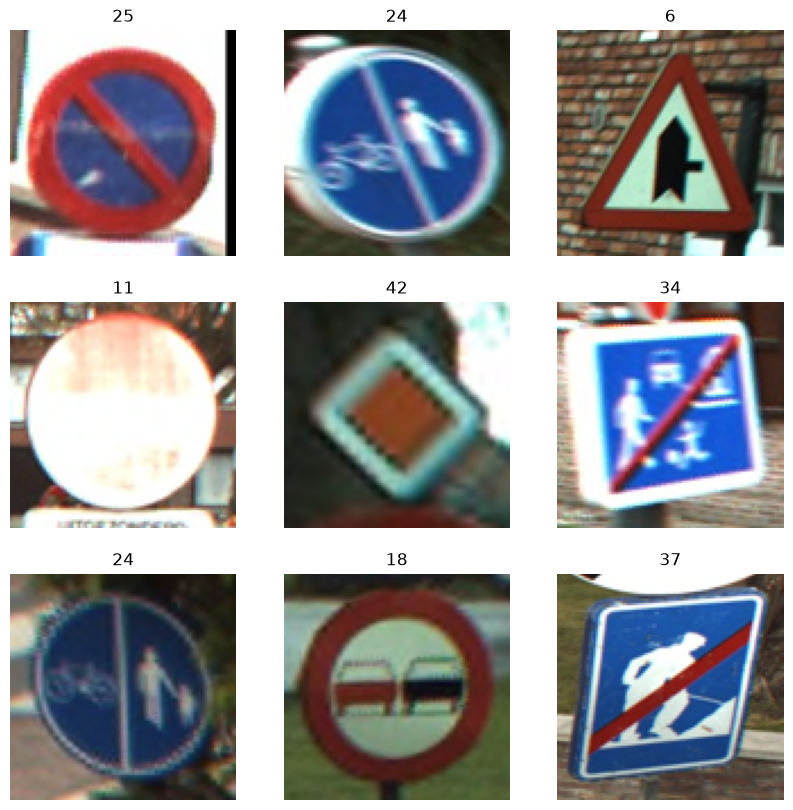

In [29]:
# Visualise nine random images
plt.figure(figsize=(10, 10))

for i in range(9):
    indx = np.random.randint(0, len(X_train))
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow((X_train[indx] * 255).astype('uint8'))
    plt.title(y_train[indx])
    plt.axis("off")

<font color='red'> **(Homework exercise 2- c)** Use one of your (best-performing) models from Task 2 of Homework 3 to train on the traffic sign image dataset. Plot the learning curves to visualize the model’s performance over time. Adjust the number of training epochs so that the process stops when the validation loss no longer improves.  **(1 point)**. </font>

In [30]:
def build_model(augmentation_layers=None, loss='sparse_categorical_crossentropy'):
  ##### YOUR CODE STARTS #####
  # Model C from Homework 3 (my best CIFAR-10 model): 3 VGG-style blocks of two 3x3 conv layers
  # with BatchNorm + ReLU, max pooling and increasing dropout, then a small dense layer.
  # Changes: input is 100x100x3 and the output has `num_classes` units.
  # Optional augmentation layers are placed right after the input (used in exercise 2-f).
  x = Input(shape=(100, 100, 3))
  t = augmentation_layers(x) if augmentation_layers is not None else x

  for filters, drop in [(32, 0.2), (64, 0.3), (128, 0.4)]:
    for _ in range(2):
      t = Conv2D(filters, (3, 3), padding='same')(t)
      t = Activation('relu')(BatchNormalization()(t))
    t = MaxPooling2D(pool_size=2)(t)
    t = Dropout(rate=drop)(t)

  t = Flatten()(t)
  t = Dense(215)(t)
  t = Activation('relu')(BatchNormalization()(t))
  t = Dropout(rate=0.5)(t)
  p = Dense(num_classes, activation='softmax')(t)

  model = Model(inputs=x, outputs=p)
  model.compile(loss=loss, optimizer=Adam(learning_rate=0.001), metrics=['accuracy'])
  return model
  ##### YOUR CODE ENDS #####

In [31]:
model1 = build_model()
model1.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 100, 100, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 100, 100, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 100, 100, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 100, 100, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 50, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 50, 50, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 50, 50, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 50, 50, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 25, 25, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 25, 25, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 25, 25, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 25, 25, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 25, 25, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 4,262,043 (16.26 MB)

 Trainable params: 4,260,717 (16.25 MB)

 Non-trainable params: 1,326 (5.18 KB)

In [32]:
histories = []

In [33]:
# Train your model.
# IMPORTANT: If you decide to resume training, ensure that you
# correctly set the initial_epoch parameter to continue from where training left
# off.
##### YOUR CODE STARTS #####
import keras
from keras.callbacks import EarlyStopping

keras.utils.set_random_seed(42)

def early_stopping():
  # stop when the validation loss has not improved for 6 epochs and go back to the best weights
  return EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=1)

history = model1.fit(X_train, y_train, batch_size=32, epochs=60, initial_epoch=0,
                     validation_data=(X_val, y_val), callbacks=[early_stopping()], verbose=2)
# 'initial_epoch' in the fit() method is a parameter that sets the epoch at
# which to start training (useful for resuming a previous training run).
##### YOUR CODE ENDS #####

histories.append(history) # In case you want to continue training but don't want
                          # to loose the training history

Epoch 1/60


49/49 - 93s - 2s/step - accuracy: 0.4405 - loss: 2.2754 - val_accuracy: 0.1421 - val_loss: 3.4092


Epoch 2/60


49/49 - 87s - 2s/step - accuracy: 0.7954 - loss: 0.8190 - val_accuracy: 0.0863 - val_loss: 3.3189


Epoch 3/60


49/49 - 72s - 1s/step - accuracy: 0.9137 - loss: 0.4167 - val_accuracy: 0.1827 - val_loss: 2.7577


Epoch 4/60


49/49 - 93s - 2s/step - accuracy: 0.9552 - loss: 0.2418 - val_accuracy: 0.5736 - val_loss: 1.4356


Epoch 5/60


49/49 - 73s - 1s/step - accuracy: 0.9751 - loss: 0.1527 - val_accuracy: 0.7817 - val_loss: 0.7986


Epoch 6/60


49/49 - 101s - 2s/step - accuracy: 0.9885 - loss: 0.1043 - val_accuracy: 0.9289 - val_loss: 0.3985


Epoch 7/60


49/49 - 90s - 2s/step - accuracy: 0.9917 - loss: 0.0692 - val_accuracy: 0.9239 - val_loss: 0.3410


Epoch 8/60


49/49 - 77s - 2s/step - accuracy: 0.9955 - loss: 0.0529 - val_accuracy: 0.9645 - val_loss: 0.2048


Epoch 9/60


49/49 - 80s - 2s/step - accuracy: 0.9987 - loss: 0.0384 - val_accuracy: 0.9645 - val_loss: 0.1574


Epoch 10/60


49/49 - 79s - 2s/step - accuracy: 0.9974 - loss: 0.0367 - val_accuracy: 0.9746 - val_loss: 0.1428


Epoch 11/60


49/49 - 77s - 2s/step - accuracy: 0.9987 - loss: 0.0289 - val_accuracy: 0.9746 - val_loss: 0.1256


Epoch 12/60


49/49 - 78s - 2s/step - accuracy: 0.9981 - loss: 0.0295 - val_accuracy: 0.9695 - val_loss: 0.1131


Epoch 13/60


49/49 - 81s - 2s/step - accuracy: 1.0000 - loss: 0.0211 - val_accuracy: 0.9746 - val_loss: 0.1263


Epoch 14/60


49/49 - 78s - 2s/step - accuracy: 1.0000 - loss: 0.0150 - val_accuracy: 0.9746 - val_loss: 0.1103


Epoch 15/60


49/49 - 80s - 2s/step - accuracy: 0.9994 - loss: 0.0156 - val_accuracy: 0.9746 - val_loss: 0.1316


Epoch 16/60


49/49 - 80s - 2s/step - accuracy: 0.9981 - loss: 0.0189 - val_accuracy: 0.9746 - val_loss: 0.1389


Epoch 17/60


49/49 - 78s - 2s/step - accuracy: 0.9994 - loss: 0.0138 - val_accuracy: 0.9746 - val_loss: 0.1146


Epoch 18/60


49/49 - 82s - 2s/step - accuracy: 0.9994 - loss: 0.0124 - val_accuracy: 0.9645 - val_loss: 0.1079


Epoch 19/60


49/49 - 75s - 2s/step - accuracy: 0.9994 - loss: 0.0138 - val_accuracy: 0.9746 - val_loss: 0.1271


Epoch 20/60


49/49 - 76s - 2s/step - accuracy: 1.0000 - loss: 0.0090 - val_accuracy: 0.9746 - val_loss: 0.1323


Epoch 21/60


49/49 - 89s - 2s/step - accuracy: 0.9994 - loss: 0.0095 - val_accuracy: 0.9695 - val_loss: 0.1174


Epoch 22/60


49/49 - 76s - 2s/step - accuracy: 1.0000 - loss: 0.0067 - val_accuracy: 0.9746 - val_loss: 0.1125


Epoch 23/60


49/49 - 76s - 2s/step - accuracy: 1.0000 - loss: 0.0068 - val_accuracy: 0.9746 - val_loss: 0.1124


Epoch 24/60


49/49 - 75s - 2s/step - accuracy: 1.0000 - loss: 0.0057 - val_accuracy: 0.9797 - val_loss: 0.1122


Epoch 24: early stopping


Restoring model weights from the end of the best epoch: 18.


In [34]:
def plot_history(histories):
    combined_loss = []
    combined_val_loss = []
    combined_accuracy = []
    combined_val_accuracy = []

    for history in histories:
        combined_loss.extend(history.history['loss'])
        combined_val_loss.extend(history.history['val_loss'])
        combined_accuracy.extend(history.history['accuracy'])
        combined_val_accuracy.extend(history.history['val_accuracy'])

    epochs = range(1, len(combined_loss) + 1)

    plt.figure(figsize=(16, 6))

    # Plot for Loss
    plt.subplot(1, 2, 1)
    plt.plot(combined_loss)
    plt.plot(combined_val_loss)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'])
    plt.title('Loss')
    plt.xticks(range(len(combined_loss)), epochs)

    # Plot for Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(combined_accuracy)
    plt.plot(combined_val_accuracy)
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'])
    plt.title('Accuracy')
    plt.xticks(range(len(combined_accuracy)), epochs)

    plt.show()

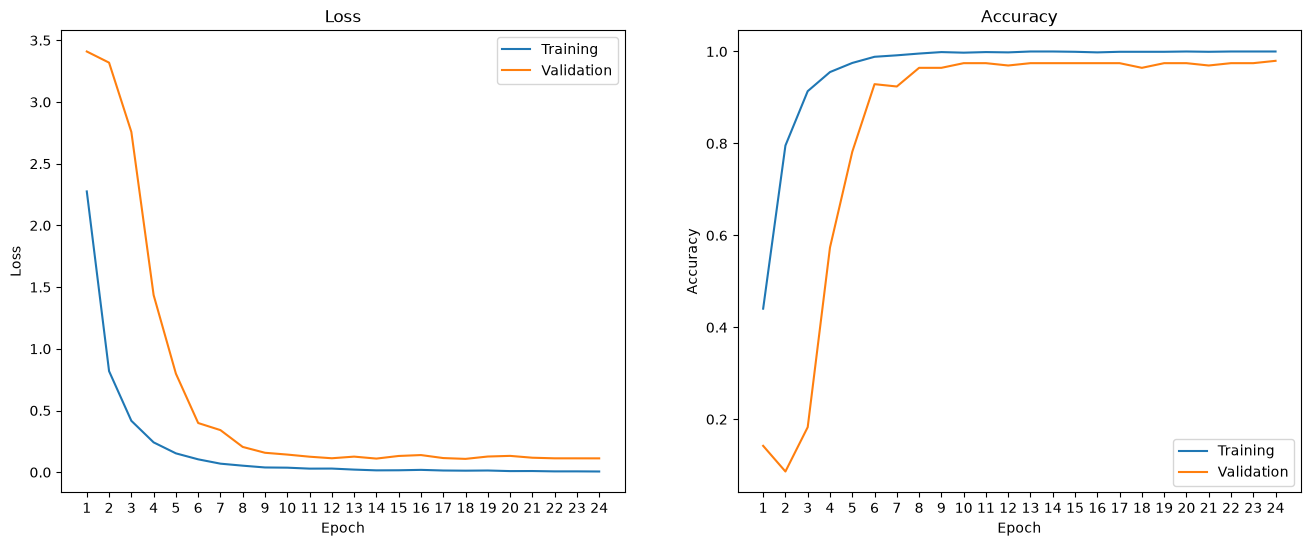

In [35]:
plot_history(histories)

 <font color='red'> **(Homework exercise 2- d)**
Evaluate the model by calculating the overall accuracy as well as the accuracy for each individual class on the test set **(0.5 points)**.</font>

In [36]:
def get_predictions(model, X):

  # Make predictions
  y_pred = model.predict(X, batch_size = 64)
  # Convert the predicted probabilities to class labels by
  # taking the index of the highest value for each prediction
  y_pred = np.argmax(y_pred, axis=1)

  return y_pred

In [37]:
y_test_predictions = get_predictions(model1, X_test)

In [38]:
# Calulate the overall accuracy on test set
##### YOUR CODE STARTS #####
test_accuracy = np.mean(y_test_predictions == y_test)
##### YOUR CODE ENDS #####
print(f'Test accuracy is {test_accuracy:.2f}') # It should be about 90%

Test accuracy is 0.97


In [39]:
# Calulate accuracy for each individual class on test set
def per_class_accuracy_score(predictions, labels):
  ##### YOUR CODE STARTS #####
  df = pd.DataFrame({'class': labels, 'correct': predictions == labels})
  per_class = df.groupby('class')['correct'].agg(test_images='size', correct='sum', accuracy='mean')
  per_class['accuracy'] = per_class['accuracy'].round(2)
  zero = per_class.index[per_class['accuracy'] == 0].tolist()
  print(f'Classes with zero accuracy: {len(zero)} of {len(per_class)} {zero}')
  return per_class
  ##### YOUR CODE ENDS #####

In [40]:
# Print out computed accuracies
per_class_accuracy_score(y_test_predictions, y_test)

Classes with zero accuracy: 2 of 43 [33, 40]


,test_images,correct,accuracy
class,,,
0,4,4,1.00
1,7,7,1.00
2,1,1,1.00
3,1,1,1.00
4,4,4,1.00
5,2,2,1.00
6,8,8,1.00
7,7,7,1.00
8,12,12,1.00


<font color='red'> For how many classes your model showed zero accuracy?

Your answer: **2 classes** (class 33 and class 40) have 0% accuracy (overall test accuracy 0.97, 6 mistakes out of 197 test images). Both classes have only **1 image in the test set** (and only 6 images in the training set), so a single mistake gives 0% for the whole class. This also shows the limitation of per-class accuracy on such a small test set: many classes have 1–2 test images, so their accuracy can only be 0%, 50% or 100%.

<font color='red'> **(Homework exercise 2- e)** Implement a basic oversampling strategy by duplicating images until each class has at least `n` samples in the training set. Choose `n` yourself. Train the model on oversampled training set and evaluate on the test set. Adjust the number of epochs so that the training stops when the validation loss stops improving. **(1.5 points)**. </font>

In [41]:
def oversample_minority_classes(df, n):
  ##### YOUR CODE STARTS #####
  # duplicate randomly chosen images of every class that has fewer than n images, until it has n
  parts = []
  for cls, group in df.groupby('ClassId'):
    if len(group) < n:
      extra = group.sample(n - len(group), replace=True, random_state=42)
      group = pd.concat([group, extra])
    parts.append(group)
  return pd.concat(parts).sample(frac=1, random_state=42).reset_index(drop=True)
  ##### YOUR CODE ENDS #####

In [42]:
# Now choose value n wisely
print('Images per class in the training set: min', train_df.ClassId.value_counts().min(),
      ', median', int(train_df.ClassId.value_counts().median()), ', max', train_df.ClassId.value_counts().max())
oversampled_train_df = oversample_minority_classes(train_df, n = 50)

Images per class in the training set: min 6 , median 27 , max 116


In [43]:
len(oversampled_train_df)

2496

<font color='red'> What value of `n` did you choose and why?

Your answer: I chose **n = 50**. In the training set the classes have between 6 and 116 images (median 27).

* n = 50 is about twice the median, so every rare class becomes at least half as large as a typical "big" class, and the network sees the rare classes much more often during training.
* I did **not** oversample everything up to the largest class (116): a class with 6 images would then contain every image ~19 times. Copies add no new information, so the network would simply memorise these 6 pictures (overfitting), and the training set would grow from 1564 to ~5000 images, making every epoch 3x slower.
* With n = 50 the duplication factor is at most ~8x and the training set grows only to 2496 images. Classes that already have ≥ 50 images are left untouched, so their real distribution is not changed.

In [44]:
X_train_oversampled = []

for i, row in oversampled_train_df.iterrows():
  X_train_oversampled.append(load_image(dataset_path + row['Filepath']))

X_train_oversampled = np.stack(X_train_oversampled)

y_train_oversampled = oversampled_train_df['ClassId'].values

In [45]:
# We use the same model as in subtask 2-c
model2 = build_model()

In [46]:
histories_2 = []

In [47]:
# Train your model2 with a new oversampled dataset

##### YOUR CODE STARTS #####
keras.utils.set_random_seed(42)
model2 = build_model()  # re-create, so the weights are fresh and the random seed is the same as for model1
history = model2.fit(X_train_oversampled, y_train_oversampled, batch_size=32, epochs=60,
                     validation_data=(X_val, y_val), callbacks=[early_stopping()], verbose=2)
##### YOUR CODE ENDS #####

histories_2.append(history) # In case you want to continue training the model
# for more epochs but don't want to loose the training history

Epoch 1/60


78/78 - 145s - 2s/step - accuracy: 0.5284 - loss: 1.8958 - val_accuracy: 0.0761 - val_loss: 4.1727


Epoch 2/60


78/78 - 110s - 1s/step - accuracy: 0.9383 - loss: 0.3682 - val_accuracy: 0.1523 - val_loss: 2.8278


Epoch 3/60


78/78 - 110s - 1s/step - accuracy: 0.9828 - loss: 0.1494 - val_accuracy: 0.5635 - val_loss: 1.5161


Epoch 4/60


78/78 - 144s - 2s/step - accuracy: 0.9904 - loss: 0.1015 - val_accuracy: 0.8629 - val_loss: 0.5712


Epoch 5/60


78/78 - 110s - 1s/step - accuracy: 0.9940 - loss: 0.0586 - val_accuracy: 0.9695 - val_loss: 0.2249


Epoch 6/60


78/78 - 127s - 2s/step - accuracy: 0.9972 - loss: 0.0437 - val_accuracy: 0.9746 - val_loss: 0.1223


Epoch 7/60


78/78 - 122s - 2s/step - accuracy: 0.9980 - loss: 0.0261 - val_accuracy: 0.9746 - val_loss: 0.1198


Epoch 8/60


78/78 - 160s - 2s/step - accuracy: 0.9996 - loss: 0.0191 - val_accuracy: 0.9797 - val_loss: 0.0952


Epoch 9/60


78/78 - 145s - 2s/step - accuracy: 0.9980 - loss: 0.0219 - val_accuracy: 0.9797 - val_loss: 0.0939


Epoch 10/60


78/78 - 113s - 1s/step - accuracy: 0.9996 - loss: 0.0143 - val_accuracy: 0.9695 - val_loss: 0.1032


Epoch 11/60


78/78 - 145s - 2s/step - accuracy: 0.9996 - loss: 0.0123 - val_accuracy: 0.9746 - val_loss: 0.0960


Epoch 12/60


78/78 - 101s - 1s/step - accuracy: 1.0000 - loss: 0.0108 - val_accuracy: 0.9746 - val_loss: 0.1115


Epoch 13/60


78/78 - 91s - 1s/step - accuracy: 1.0000 - loss: 0.0101 - val_accuracy: 0.9797 - val_loss: 0.1054


Epoch 14/60


78/78 - 98s - 1s/step - accuracy: 1.0000 - loss: 0.0081 - val_accuracy: 0.9746 - val_loss: 0.1052


Epoch 15/60


78/78 - 130s - 2s/step - accuracy: 1.0000 - loss: 0.0063 - val_accuracy: 0.9797 - val_loss: 0.0970


Epoch 15: early stopping


Restoring model weights from the end of the best epoch: 9.


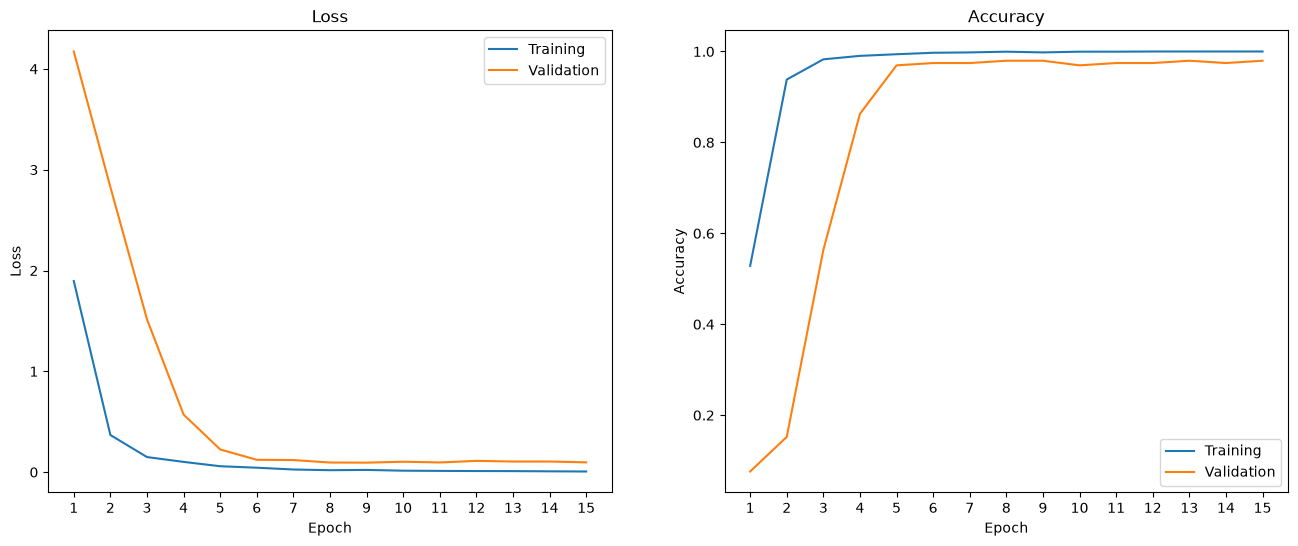

In [48]:
plot_history(histories_2)

In [49]:
y_test_predictions = get_predictions(model2, X_test)

In [50]:
# Calulate the overall accuracy on test set
##### YOUR CODE STARTS #####
test_accuracy = np.mean(y_test_predictions == y_test)
##### YOUR CODE ENDS #####
print(f'Test accuracy is {test_accuracy:.2f}')

Test accuracy is 0.98


In [51]:
# Accuracy for each individual class on test set
per_class_accuracy_score(y_test_predictions, y_test)

Classes with zero accuracy: 1 of 43 [33]

,test_images,correct,accuracy
class,,,
0,4,4,1.00
1,7,7,1.00
2,1,1,1.00
3,1,1,1.00
4,4,4,1.00
5,2,2,1.00
6,8,8,1.00
7,7,7,1.00
8,12,12,1.00


<font color='red'> For how many classes your model showed zero accuracy? Is the number smaller than in EX2-d?

Your answer: Now only **1 class** (class 33) has 0% accuracy – fewer than in 2-d (2 classes). Class 40 is now recognised correctly, the overall test accuracy rose from 0.97 to 0.98, and the mean per-class accuracy from 0.92 to 0.96 (see the comparison table in the bonus part). The validation loss also reached a lower minimum (0.094 vs 0.108). So oversampling helped the rare classes a bit, because the model now gets more gradient updates from them. But the test set is tiny: the difference between the two models is just 2 test images, so it should not be over-interpreted. The model still fails on class 33, which has only one test image.

<font color='red'> **(Homework exercise 2- f)** Add three augmentations to the oversampled training data using augmentation layers from `keras` image augmentation layers (https://keras.io/api/layers/preprocessing_layers/image_augmentation/). Think about reasonable augmentations for this dataset. Train the model on augmented data and evaluate it on the test data. Again, adjust the number of epochs so that the training stops when the validation loss stops improving. **(1.5 points)**.

NOTE: In the practice session we did not use Input(shape=...) at the beginning of our augmentation layers. If input shape is not explicitly provided, `keras` automatically infers it when the augmentation layers are used for the first time. Here, the first usage is for visualization (batch size 8), while the network expects a different batch size. Adding Input(shape=100, 100, 3) avoids having to re-create the augmentation layers object when switching between visualization and training a network - use it!
</font>

In [52]:
##### YOUR CODE STARTS #####
from keras.layers import RandomRotation, RandomZoom, RandomBrightness
from keras import Sequential

augmentation_layers = Sequential([
    Input(shape=(100, 100, 3)),
    # small rotation: +-0.04 * 360 = +-14 degrees (signs are photographed slightly tilted)
    RandomRotation(factor=0.04, fill_mode='nearest'),
    # zoom in/out by up to 15% (signs are photographed from different distances, crops are not tight)
    RandomZoom(height_factor=(-0.15, 0.15), fill_mode='nearest'),
    # brighter / darker image (day, dusk, shadows); our pixel values are in [0, 1]
    RandomBrightness(factor=0.25, value_range=(0, 1)),
], name='augmentation')
##### YOUR CODE ENDS #####

<font color='red'> Make sure that the augmentations aren't too strong and do not distort the images too much. Plot pairs of original and augmented images to verify.

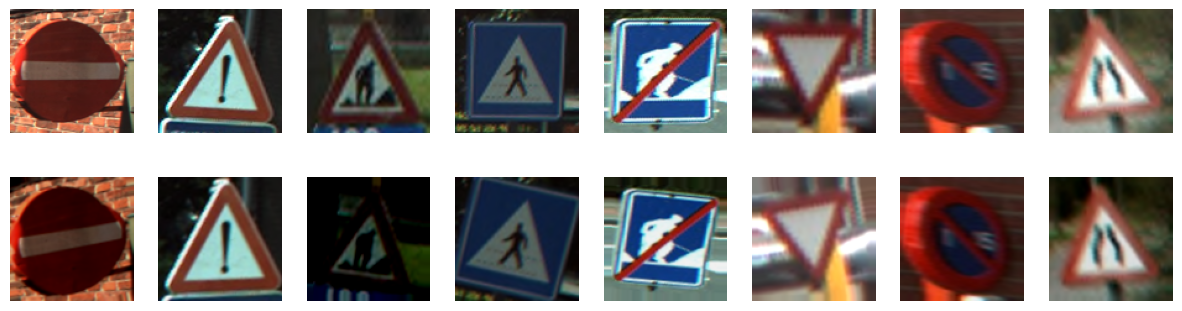

In [53]:
from matplotlib import pyplot as plt

n = 8
sample = np.random.choice(X_train_oversampled.shape[0], size=n, replace=False)
originals = X_train_oversampled[sample]
augmented = np.asarray(augmentation_layers(originals))

plt.figure(figsize=(15, 4))
for i in range(n):
    plt.subplot(2, n, 1 + i)          # top row: original
    plt.imshow(originals[i])
    plt.axis('off')

    plt.subplot(2, n, n + 1 + i)      # bottom row: augmented
    plt.imshow(augmented[i])
    plt.axis('off')
plt.show()

<font color='red'> Explain in your words why did you choose these augmentations.

Your answer: The augmentations should create images that could really be taken by a car camera, without changing the meaning of the sign:

* **Small rotation (±14°)** – signs are often slightly tilted, or the camera is not perfectly level. Large rotations are not used: a sign rotated by 90° or 180° does not occur on the road and some signs (e.g. arrows, "priority road" diamond vs. square) change their meaning when rotated a lot.
* **Zoom in / out (±15%)** – the sign is photographed from different distances and the crops around the sign are not equally tight, so the size and position of the sign inside the 100×100 image varies.
* **Brightness (±25%)** – the photos are taken in sun, shade, dusk or with back-light, so the same sign has very different brightness.

I deliberately did **not** use flips: a horizontal flip turns "turn left" into "turn right" and mirrors text/numbers, i.e. it would create images with a wrong label; a vertical flip produces upside-down signs that never appear in reality. Colour changes (hue) were also avoided, because colour (red/blue/yellow) is an important part of the sign meaning.

<font color='red'> Recall that data Keras data augmentation layers can be part of the network, inserted right after the input layer. These layers are used during fit() and skipped during predict() calls automatically. Modify the code for the neural network you used above in exercise 2-c by adding the augmentation layer(s) after the input layer.

<font color='red'>Then build, train on oversampled training data, plot accuracy and loss curves, and evaluate your model on the test data.

In [54]:
def build_model_augmentation(augmentation_layers):
  ##### YOUR CODE STARTS #####
  # the same network as in 2-c, with the augmentation layers inserted right after the input layer
  return build_model(augmentation_layers=augmentation_layers)
  ##### YOUR CODE ENDS #####

In [55]:
# Create an instance of the new model
model3 = build_model_augmentation(augmentation_layers)

In [56]:
histories_3 = []

In [57]:
# Train your model3
##### YOUR CODE STARTS #####
keras.utils.set_random_seed(42)
model3 = build_model_augmentation(augmentation_layers)
# augmented images are harder, so the model needs more epochs: larger maximum and more patience
history = model3.fit(X_train_oversampled, y_train_oversampled, batch_size=32, epochs=100,
                     validation_data=(X_val, y_val),
                     callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)],
                     verbose=2)
##### YOUR CODE ENDS #####

histories_3.append(history)

Epoch 1/100


78/78 - 84s - 1s/step - accuracy: 0.3930 - loss: 2.3530 - val_accuracy: 0.0761 - val_loss: 3.9063


Epoch 2/100


78/78 - 82s - 1s/step - accuracy: 0.8281 - loss: 0.7122 - val_accuracy: 0.2792 - val_loss: 2.2396


Epoch 3/100


78/78 - 77s - 988ms/step - accuracy: 0.9287 - loss: 0.3605 - val_accuracy: 0.8020 - val_loss: 0.6872


Epoch 4/100


78/78 - 154s - 2s/step - accuracy: 0.9551 - loss: 0.2549 - val_accuracy: 0.9289 - val_loss: 0.2860


Epoch 5/100


78/78 - 182s - 2s/step - accuracy: 0.9579 - loss: 0.1980 - val_accuracy: 0.9746 - val_loss: 0.1147


Epoch 6/100


78/78 - 136s - 2s/step - accuracy: 0.9744 - loss: 0.1506 - val_accuracy: 0.9746 - val_loss: 0.0817


Epoch 7/100


78/78 - 128s - 2s/step - accuracy: 0.9792 - loss: 0.1143 - val_accuracy: 0.9797 - val_loss: 0.0734


Epoch 8/100


78/78 - 126s - 2s/step - accuracy: 0.9836 - loss: 0.0904 - val_accuracy: 0.9848 - val_loss: 0.0628


Epoch 9/100


78/78 - 144s - 2s/step - accuracy: 0.9832 - loss: 0.0918 - val_accuracy: 0.9848 - val_loss: 0.0490


Epoch 10/100


78/78 - 133s - 2s/step - accuracy: 0.9860 - loss: 0.0798 - val_accuracy: 0.9797 - val_loss: 0.0691


Epoch 11/100


78/78 - 122s - 2s/step - accuracy: 0.9876 - loss: 0.0648 - val_accuracy: 0.9898 - val_loss: 0.0599


Epoch 12/100


78/78 - 137s - 2s/step - accuracy: 0.9880 - loss: 0.0620 - val_accuracy: 0.9797 - val_loss: 0.0608


Epoch 13/100


78/78 - 139s - 2s/step - accuracy: 0.9852 - loss: 0.0697 - val_accuracy: 0.9797 - val_loss: 0.0526


Epoch 14/100


78/78 - 112s - 1s/step - accuracy: 0.9868 - loss: 0.0558 - val_accuracy: 0.9746 - val_loss: 0.0594


Epoch 15/100


78/78 - 104s - 1s/step - accuracy: 0.9892 - loss: 0.0511 - val_accuracy: 0.9746 - val_loss: 0.0648


Epoch 16/100


78/78 - 128s - 2s/step - accuracy: 0.9904 - loss: 0.0483 - val_accuracy: 0.9848 - val_loss: 0.0879


Epoch 17/100


78/78 - 120s - 2s/step - accuracy: 0.9904 - loss: 0.0474 - val_accuracy: 0.9746 - val_loss: 0.0854


Epoch 18/100


78/78 - 116s - 1s/step - accuracy: 0.9900 - loss: 0.0482 - val_accuracy: 0.9797 - val_loss: 0.0544


Epoch 19/100


78/78 - 108s - 1s/step - accuracy: 0.9896 - loss: 0.0422 - val_accuracy: 0.9898 - val_loss: 0.0356


Epoch 20/100


78/78 - 139s - 2s/step - accuracy: 0.9940 - loss: 0.0332 - val_accuracy: 0.9848 - val_loss: 0.0501


Epoch 21/100


78/78 - 113s - 1s/step - accuracy: 0.9932 - loss: 0.0330 - val_accuracy: 0.9797 - val_loss: 0.0937


Epoch 22/100


78/78 - 134s - 2s/step - accuracy: 0.9964 - loss: 0.0236 - val_accuracy: 0.9848 - val_loss: 0.0620


Epoch 23/100


78/78 - 88s - 1s/step - accuracy: 0.9892 - loss: 0.0350 - val_accuracy: 0.9898 - val_loss: 0.0504


Epoch 24/100


78/78 - 120s - 2s/step - accuracy: 0.9936 - loss: 0.0335 - val_accuracy: 0.9949 - val_loss: 0.0310


Epoch 25/100


78/78 - 141s - 2s/step - accuracy: 0.9924 - loss: 0.0345 - val_accuracy: 0.9746 - val_loss: 0.0618


Epoch 26/100


78/78 - 134s - 2s/step - accuracy: 0.9932 - loss: 0.0332 - val_accuracy: 0.9492 - val_loss: 0.1170


Epoch 27/100


78/78 - 101s - 1s/step - accuracy: 0.9892 - loss: 0.0369 - val_accuracy: 0.9797 - val_loss: 0.0616


Epoch 28/100


78/78 - 112s - 1s/step - accuracy: 0.9948 - loss: 0.0250 - val_accuracy: 0.9797 - val_loss: 0.0507


Epoch 29/100


78/78 - 112s - 1s/step - accuracy: 0.9908 - loss: 0.0367 - val_accuracy: 0.9848 - val_loss: 0.0580


Epoch 30/100


78/78 - 142s - 2s/step - accuracy: 0.9936 - loss: 0.0279 - val_accuracy: 0.9746 - val_loss: 0.0669


Epoch 31/100


78/78 - 119s - 2s/step - accuracy: 0.9908 - loss: 0.0321 - val_accuracy: 0.9797 - val_loss: 0.0440


Epoch 32/100


78/78 - 148s - 2s/step - accuracy: 0.9904 - loss: 0.0390 - val_accuracy: 0.9848 - val_loss: 0.0537


Epoch 33/100


78/78 - 131s - 2s/step - accuracy: 0.9920 - loss: 0.0417 - val_accuracy: 0.9797 - val_loss: 0.0656


Epoch 34/100


78/78 - 139s - 2s/step - accuracy: 0.9956 - loss: 0.0224 - val_accuracy: 0.9746 - val_loss: 0.0628


Epoch 34: early stopping


Restoring model weights from the end of the best epoch: 24.


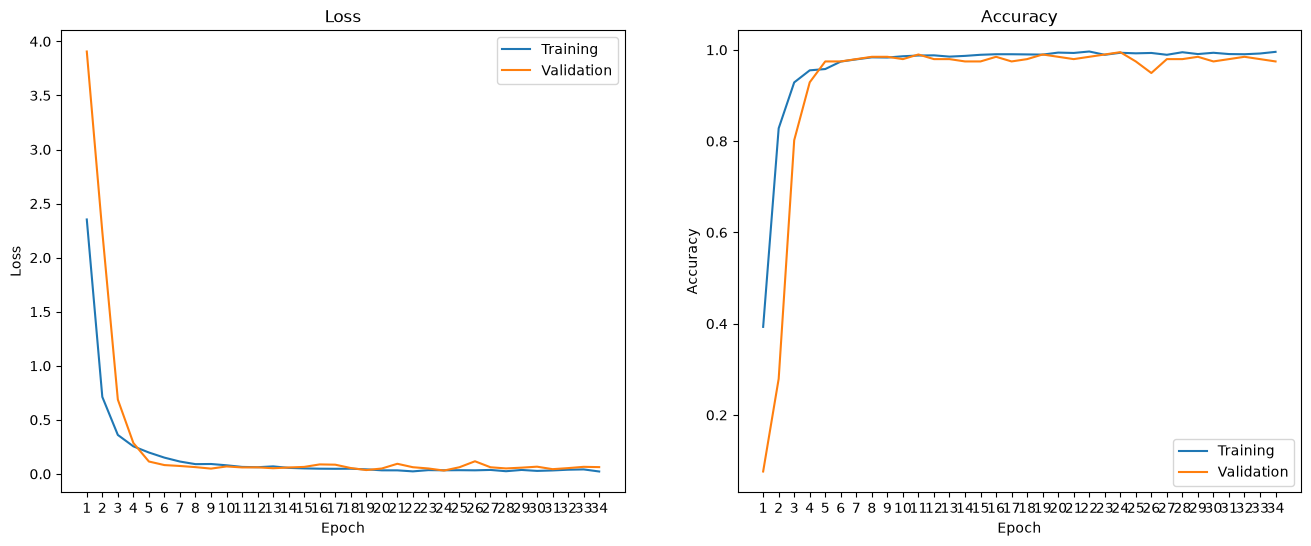

In [58]:
plot_history(histories_3)

In [59]:
y_test_predictions = get_predictions(model3, X_test)

In [60]:
# Calulate the overall accuracy on test set
##### YOUR CODE STARTS #####
test_accuracy = np.mean(y_test_predictions == y_test)
##### YOUR CODE ENDS #####
print(f'Test accuracy is {test_accuracy:.2f}')

Test accuracy is 0.99


In [61]:
# Accuracy for each individual class on test set
per_class_accuracy_score(y_test_predictions, y_test)

Classes with zero accuracy: 0 of 43 []


,test_images,correct,accuracy
class,,,
0,4,4,1.00
1,7,7,1.00
2,1,1,1.00
3,1,1,1.00
4,4,4,1.00
5,2,2,1.00
6,8,8,1.00
7,7,7,1.00
8,12,12,1.00


<font color='red'> For how many classes your model showed zero accuracy? Did the performance improve comparing to the original and naively oversampled datasets?

Your answer: **0 classes** with zero accuracy – every class is now recognised. The test accuracy is **0.99** (2 mistakes out of 197, both in large classes), compared to 0.97 on the original data (2-d) and 0.98 with naive oversampling (2-e). The mean per-class accuracy rose to 0.99, and the minimum validation loss was much lower (0.031 vs ~0.1). So yes, the performance improved compared to both.

The learning curves also look healthier: with augmentation the training accuracy no longer jumps to 100% after a few epochs (the model cannot simply memorise the duplicated images, because every copy looks slightly different each time), and the validation loss keeps improving for longer (best epoch 24 instead of 9–18). Augmentation turns the naive copies of the oversampled rare classes into genuinely new training examples, which is why the combination of oversampling + augmentation works better than oversampling alone. As before, the test set is small, so the differences are only a few images.

# Bonus exercises
**NB, these are optional exercises! You do not have to do them unless you feel like :)**


## Implement Attentive CutMix from scratch (up to 4 bonus points depending on presentation):
<font color='red'> Experimentally verify if Attentive CutMix augmentation helps to improve the test score on BelgiumTSC. Link to the Attentive CutMix paper: https://arxiv.org/pdf/2003.13048. Implement and show couple of examples images augmented with Attentive CutMix. Test its performance and visualise the corresponding accuracy and loss curves. Compare the results of model trained on Attentive CutMix augmented images to the model trained with regular data augmentation. </font>


### Attentive CutMix on BelgiumTSC

**Idea.** [CutMix](https://arxiv.org/abs/1905.04899) cuts a random rectangle from one training image and pastes it onto another one; the label is mixed in proportion to the pasted area. The problem: a random rectangle often contains only background (sky, a pole, a building), but the label still says "30% of class B" – the label becomes noisy. **Attentive CutMix** ([Walawalkar et al., 2020](https://arxiv.org/pdf/2003.13048)) fixes this by pasting only the *most important* parts of image B:

1. A pretrained CNN (the paper uses ResNet-50 trained on ImageNet) gives a 7×7 feature map for image B. Each of the 49 cells corresponds to a 1/7 × 1/7 patch of the image, and its activation tells how "interesting" (object-like) this patch is.
2. The top-*k* cells (the paper uses *k* = 6) are selected; the corresponding patches of image B are pasted onto image A at the **same positions**.
3. The new label is a mix: `y = (1 − λ)·y_A + λ·y_B` with `λ = k / 49` – the fraction of the image that was replaced.

Below I implement it from scratch: the attention maps, the mixing, a `keras.utils.PyDataset` that creates new mixed batches every epoch, and then compare against the models from exercise 2.

In [62]:
# Step 1: attention maps from a pretrained ResNet-50 (ImageNet weights, no classification head)
from keras.applications import ResNet50
from keras.applications.resnet50 import preprocess_input

GRID = 7     # ResNet-50 at 224x224 input gives a 7x7 feature map
TOP_K = 6    # number of patches to paste, as in the paper
LAMBDA = TOP_K / GRID**2

feature_extractor = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

def attention_maps(images, batch_size=64):
    """images in [0, 1], shape (N, 100, 100, 3) -> (N, 7, 7) attention maps (mean activation over channels)."""
    maps = []
    for start in range(0, len(images), batch_size):
        batch = tf.image.resize(images[start:start + batch_size], (224, 224)) * 255.0
        features = feature_extractor(preprocess_input(batch), training=False)   # (b, 7, 7, 2048)
        maps.append(tf.reduce_mean(features, axis=-1).numpy())
    return np.concatenate(maps)

train_attention = attention_maps(X_train_oversampled)
print('attention maps:', train_attention.shape)

attention maps: (2496, 7, 7)


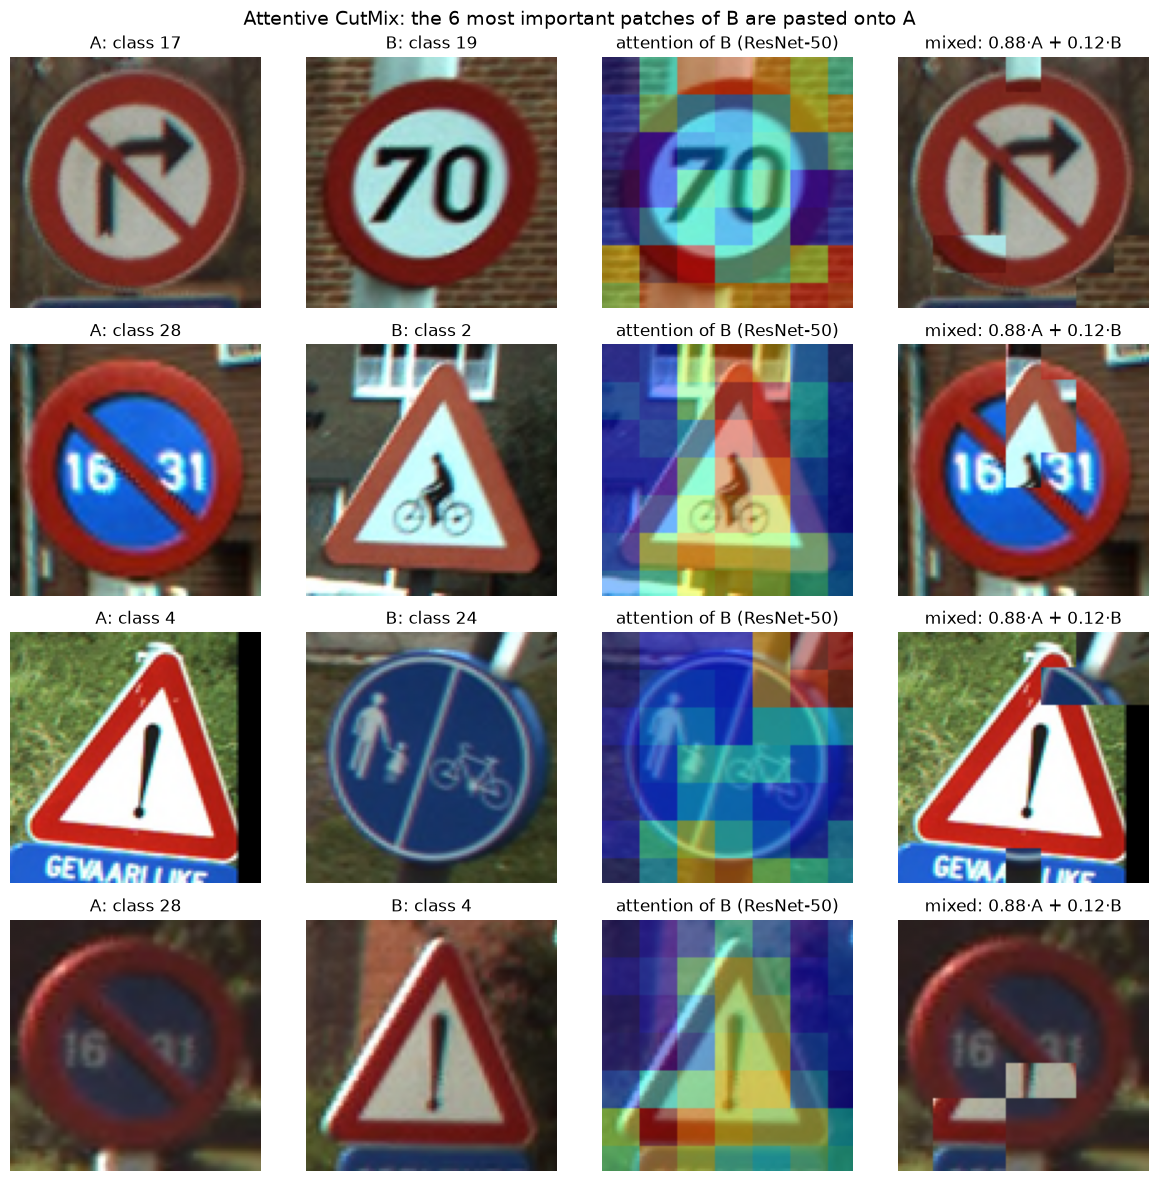

In [63]:
# Step 2: the mixing operation
cell_edges = np.round(np.linspace(0, 100, GRID + 1)).astype(int)   # pixel borders of the 7x7 grid on a 100x100 image

def top_k_mask(attention, k=TOP_K):
    """7x7 attention map -> 100x100x1 binary mask that is 1 on the k most important patches."""
    mask = np.zeros((100, 100, 1), dtype='float32')
    for cell in np.argsort(attention.ravel())[-k:]:
        r, c = divmod(cell, GRID)
        mask[cell_edges[r]:cell_edges[r + 1], cell_edges[c]:cell_edges[c + 1]] = 1.0
    return mask

def attentive_cutmix(img_a, img_b, attention_b, k=TOP_K):
    mask = top_k_mask(attention_b, k)
    return img_a * (1 - mask) + img_b * mask, mask

# Step 3: show a few examples: image A, image B with its attention map, result
rng = np.random.default_rng(0)
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for row in range(4):
    a, b = rng.choice(len(X_train_oversampled), size=2, replace=False)
    mixed, mask = attentive_cutmix(X_train_oversampled[a], X_train_oversampled[b], train_attention[b])
    axes[row, 0].imshow(X_train_oversampled[a]); axes[row, 0].set_title(f'A: class {y_train_oversampled[a]}')
    axes[row, 1].imshow(X_train_oversampled[b]); axes[row, 1].set_title(f'B: class {y_train_oversampled[b]}')
    axes[row, 2].imshow(X_train_oversampled[b])
    axes[row, 2].imshow(np.kron(train_attention[b], np.ones((15, 15)))[:100, :100], cmap='jet', alpha=0.45)
    axes[row, 2].set_title('attention of B (ResNet-50)')
    axes[row, 3].imshow(mixed)
    axes[row, 3].set_title(f'mixed: {1-LAMBDA:.2f}·A + {LAMBDA:.2f}·B')
    for ax in axes[row]:
        ax.axis('off')
plt.suptitle(f'Attentive CutMix: the {TOP_K} most important patches of B are pasted onto A', fontsize=14)
plt.tight_layout()
plt.show()

The attention of the pretrained network is mostly on the sign itself (its border, symbols and colours), not on the background, so the pasted patches really carry information about class B. Because only 6/49 ≈ 12% of the image is replaced, image A stays recognisable – the network has to learn to recognise a sign even when parts of it are covered by another sign, and to output a "softer" probability (88% A, 12% B) instead of being 100% sure.

**Training data generator.** Every epoch new pairs are drawn, so the model never sees exactly the same mixed image twice. Following the usual CutMix practice, each image is mixed with probability 0.5 (the other half of the batch stays unchanged), so the network still sees whole signs. Labels are one-hot vectors, so the model is compiled with `categorical_crossentropy`.

In [64]:
# Step 4: a data generator that applies Attentive CutMix on the fly
class AttentiveCutMixData(keras.utils.PyDataset):
    def __init__(self, images, labels, attention, batch_size=32, mix_prob=0.5, seed=42, **kwargs):
        super().__init__(**kwargs)
        self.images, self.labels, self.attention = images, labels, attention
        self.batch_size, self.mix_prob = batch_size, mix_prob
        self.rng = np.random.default_rng(seed)
        self.order = self.rng.permutation(len(images))

    def __len__(self):
        return int(np.ceil(len(self.images) / self.batch_size))

    def __getitem__(self, idx):
        batch = self.order[idx * self.batch_size:(idx + 1) * self.batch_size]
        x = self.images[batch].astype('float32')
        y = keras.utils.to_categorical(self.labels[batch], num_classes).astype('float32')
        for i in range(len(batch)):
            if self.rng.random() < self.mix_prob:
                j = self.rng.integers(len(self.images))           # partner image B
                x[i], _ = attentive_cutmix(x[i], self.images[j], self.attention[j])
                y[i] = (1 - LAMBDA) * y[i] + LAMBDA * keras.utils.to_categorical(self.labels[j], num_classes)
        return x, y

    def on_epoch_end(self):
        self.order = self.rng.permutation(len(self.images))

y_val_onehot = keras.utils.to_categorical(y_val, num_classes)

Epoch 1/100


78/78 - 94s - 1s/step - accuracy: 0.4239 - loss: 2.3759 - val_accuracy: 0.1269 - val_loss: 3.6065


Epoch 2/100


78/78 - 92s - 1s/step - accuracy: 0.8333 - loss: 0.9722 - val_accuracy: 0.1929 - val_loss: 2.9282


Epoch 3/100


78/78 - 90s - 1s/step - accuracy: 0.9167 - loss: 0.7060 - val_accuracy: 0.6447 - val_loss: 1.4112


Epoch 4/100


78/78 - 79s - 1s/step - accuracy: 0.9379 - loss: 0.6253 - val_accuracy: 0.9442 - val_loss: 0.4220


Epoch 5/100


78/78 - 52s - 669ms/step - accuracy: 0.9467 - loss: 0.5969 - val_accuracy: 0.9594 - val_loss: 0.2390


Epoch 6/100


78/78 - 49s - 634ms/step - accuracy: 0.9567 - loss: 0.5655 - val_accuracy: 0.9442 - val_loss: 0.1953


Epoch 7/100


78/78 - 76s - 972ms/step - accuracy: 0.9591 - loss: 0.5565 - val_accuracy: 0.9645 - val_loss: 0.1621


Epoch 8/100


78/78 - 76s - 978ms/step - accuracy: 0.9667 - loss: 0.5251 - val_accuracy: 0.9594 - val_loss: 0.1935


Epoch 9/100


78/78 - 69s - 888ms/step - accuracy: 0.9720 - loss: 0.5236 - val_accuracy: 0.9594 - val_loss: 0.1491


Epoch 10/100


78/78 - 69s - 883ms/step - accuracy: 0.9764 - loss: 0.4882 - val_accuracy: 0.9645 - val_loss: 0.1418


Epoch 11/100


78/78 - 56s - 715ms/step - accuracy: 0.9728 - loss: 0.5046 - val_accuracy: 0.9645 - val_loss: 0.1490


Epoch 12/100


78/78 - 50s - 644ms/step - accuracy: 0.9760 - loss: 0.4744 - val_accuracy: 0.9645 - val_loss: 0.1339


Epoch 13/100


78/78 - 82s - 1s/step - accuracy: 0.9704 - loss: 0.5004 - val_accuracy: 0.9543 - val_loss: 0.1632


Epoch 14/100


78/78 - 112s - 1s/step - accuracy: 0.9732 - loss: 0.4878 - val_accuracy: 0.9746 - val_loss: 0.1090


Epoch 15/100


78/78 - 86s - 1s/step - accuracy: 0.9760 - loss: 0.4668 - val_accuracy: 0.9746 - val_loss: 0.1185


Epoch 16/100


78/78 - 139s - 2s/step - accuracy: 0.9748 - loss: 0.4501 - val_accuracy: 0.9797 - val_loss: 0.1174


Epoch 17/100


78/78 - 83s - 1s/step - accuracy: 0.9796 - loss: 0.4675 - val_accuracy: 0.9695 - val_loss: 0.1262


Epoch 18/100


78/78 - 64s - 823ms/step - accuracy: 0.9780 - loss: 0.4808 - val_accuracy: 0.9543 - val_loss: 0.1474


Epoch 19/100


78/78 - 83s - 1s/step - accuracy: 0.9780 - loss: 0.4579 - val_accuracy: 0.9645 - val_loss: 0.1570


Epoch 20/100


78/78 - 73s - 933ms/step - accuracy: 0.9844 - loss: 0.4371 - val_accuracy: 0.9797 - val_loss: 0.0977


Epoch 21/100


78/78 - 67s - 858ms/step - accuracy: 0.9792 - loss: 0.4591 - val_accuracy: 0.9746 - val_loss: 0.1115


Epoch 22/100


78/78 - 70s - 898ms/step - accuracy: 0.9792 - loss: 0.4610 - val_accuracy: 0.9695 - val_loss: 0.1273


Epoch 23/100


78/78 - 61s - 778ms/step - accuracy: 0.9856 - loss: 0.4319 - val_accuracy: 0.9695 - val_loss: 0.1127


Epoch 24/100


78/78 - 67s - 854ms/step - accuracy: 0.9832 - loss: 0.4385 - val_accuracy: 0.9594 - val_loss: 0.1405


Epoch 25/100


78/78 - 84s - 1s/step - accuracy: 0.9744 - loss: 0.4359 - val_accuracy: 0.9645 - val_loss: 0.1523


Epoch 26/100


78/78 - 100s - 1s/step - accuracy: 0.9764 - loss: 0.4568 - val_accuracy: 0.9645 - val_loss: 0.1177


Epoch 27/100


78/78 - 130s - 2s/step - accuracy: 0.9752 - loss: 0.4332 - val_accuracy: 0.9695 - val_loss: 0.1375


Epoch 28/100


78/78 - 95s - 1s/step - accuracy: 0.9820 - loss: 0.4319 - val_accuracy: 0.9543 - val_loss: 0.1250


Epoch 29/100


78/78 - 92s - 1s/step - accuracy: 0.9816 - loss: 0.4361 - val_accuracy: 0.9695 - val_loss: 0.1668


Epoch 30/100


78/78 - 87s - 1s/step - accuracy: 0.9776 - loss: 0.4477 - val_accuracy: 0.9695 - val_loss: 0.1462


Epoch 30: early stopping


Restoring model weights from the end of the best epoch: 20.


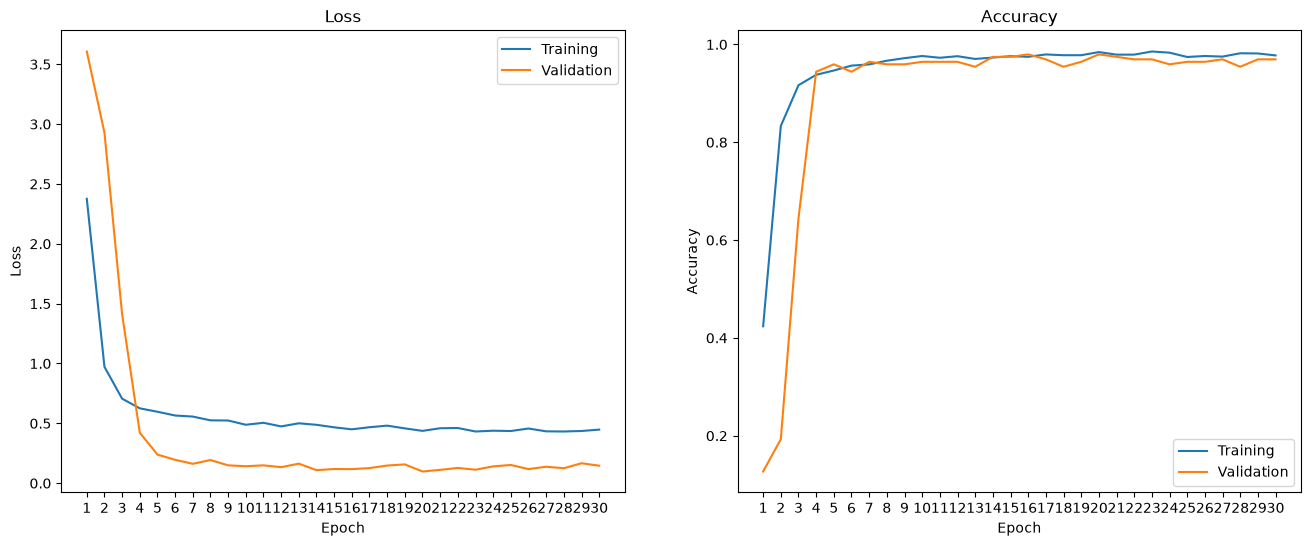

In [65]:
# Step 5a: same network as in 2-c/2-e, trained on the oversampled data with Attentive CutMix only
keras.utils.set_random_seed(42)
model_acm = build_model(loss='categorical_crossentropy')
history_acm = model_acm.fit(AttentiveCutMixData(X_train_oversampled, y_train_oversampled, train_attention),
                            epochs=100, validation_data=(X_val, y_val_onehot),
                            callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)],
                            verbose=2)
plot_history([history_acm])

Epoch 1/100


78/78 - 100s - 1s/step - accuracy: 0.2804 - loss: 2.8710 - val_accuracy: 0.2690 - val_loss: 3.0975


Epoch 2/100


78/78 - 86s - 1s/step - accuracy: 0.6695 - loss: 1.3947 - val_accuracy: 0.3858 - val_loss: 2.1700


Epoch 3/100


78/78 - 67s - 863ms/step - accuracy: 0.8013 - loss: 1.0261 - val_accuracy: 0.8325 - val_loss: 0.6837


Epoch 4/100


78/78 - 85s - 1s/step - accuracy: 0.8490 - loss: 0.9008 - val_accuracy: 0.9137 - val_loss: 0.3339


Epoch 5/100


78/78 - 85s - 1s/step - accuracy: 0.8578 - loss: 0.8371 - val_accuracy: 0.9645 - val_loss: 0.1881


Epoch 6/100


78/78 - 70s - 893ms/step - accuracy: 0.8794 - loss: 0.7975 - val_accuracy: 0.9695 - val_loss: 0.1382


Epoch 7/100


78/78 - 90s - 1s/step - accuracy: 0.8790 - loss: 0.7821 - val_accuracy: 0.9695 - val_loss: 0.1181


Epoch 8/100


78/78 - 220s - 3s/step - accuracy: 0.9095 - loss: 0.7071 - val_accuracy: 0.9746 - val_loss: 0.1052


Epoch 9/100


78/78 - 100s - 1s/step - accuracy: 0.9183 - loss: 0.6801 - val_accuracy: 0.9797 - val_loss: 0.0825


Epoch 10/100


78/78 - 70s - 898ms/step - accuracy: 0.9243 - loss: 0.6620 - val_accuracy: 0.9848 - val_loss: 0.1032


Epoch 11/100


78/78 - 98s - 1s/step - accuracy: 0.9095 - loss: 0.6911 - val_accuracy: 0.9746 - val_loss: 0.0863


Epoch 12/100


78/78 - 87s - 1s/step - accuracy: 0.9183 - loss: 0.6408 - val_accuracy: 0.9594 - val_loss: 0.1030


Epoch 13/100


78/78 - 69s - 882ms/step - accuracy: 0.9279 - loss: 0.6531 - val_accuracy: 0.9746 - val_loss: 0.1145


Epoch 14/100


78/78 - 62s - 799ms/step - accuracy: 0.9271 - loss: 0.6496 - val_accuracy: 0.9848 - val_loss: 0.0798


Epoch 15/100


78/78 - 83s - 1s/step - accuracy: 0.9367 - loss: 0.6170 - val_accuracy: 0.9746 - val_loss: 0.0723


Epoch 16/100


78/78 - 70s - 893ms/step - accuracy: 0.9347 - loss: 0.6037 - val_accuracy: 0.9848 - val_loss: 0.0577


Epoch 17/100


78/78 - 63s - 807ms/step - accuracy: 0.9419 - loss: 0.6081 - val_accuracy: 0.9746 - val_loss: 0.0814


Epoch 18/100


78/78 - 68s - 876ms/step - accuracy: 0.9419 - loss: 0.6104 - val_accuracy: 0.9797 - val_loss: 0.0891


Epoch 19/100


78/78 - 66s - 841ms/step - accuracy: 0.9359 - loss: 0.6107 - val_accuracy: 0.9695 - val_loss: 0.1391


Epoch 20/100


78/78 - 67s - 856ms/step - accuracy: 0.9455 - loss: 0.5617 - val_accuracy: 0.9848 - val_loss: 0.0689


Epoch 21/100


78/78 - 70s - 902ms/step - accuracy: 0.9359 - loss: 0.5953 - val_accuracy: 0.9797 - val_loss: 0.0992


Epoch 22/100


78/78 - 66s - 841ms/step - accuracy: 0.9379 - loss: 0.6008 - val_accuracy: 0.9746 - val_loss: 0.0785


Epoch 23/100


78/78 - 66s - 840ms/step - accuracy: 0.9467 - loss: 0.5678 - val_accuracy: 0.9797 - val_loss: 0.0603


Epoch 24/100


78/78 - 74s - 946ms/step - accuracy: 0.9439 - loss: 0.5687 - val_accuracy: 0.9797 - val_loss: 0.1104


Epoch 25/100


78/78 - 70s - 897ms/step - accuracy: 0.9483 - loss: 0.5579 - val_accuracy: 0.9848 - val_loss: 0.0881


Epoch 26/100


78/78 - 72s - 925ms/step - accuracy: 0.9439 - loss: 0.5915 - val_accuracy: 0.9898 - val_loss: 0.0657


Epoch 26: early stopping


Restoring model weights from the end of the best epoch: 16.


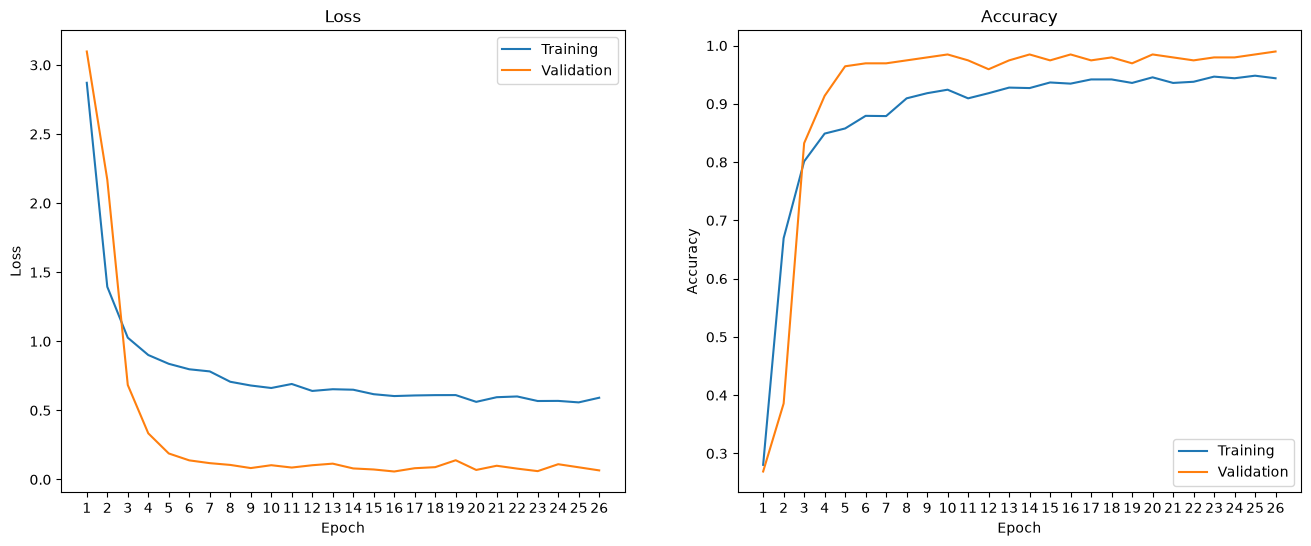

In [66]:
# Step 5b: Attentive CutMix + the regular augmentation layers from 2-f (the two can be combined)
keras.utils.set_random_seed(42)
model_acm_aug = build_model(augmentation_layers=augmentation_layers, loss='categorical_crossentropy')
history_acm_aug = model_acm_aug.fit(AttentiveCutMixData(X_train_oversampled, y_train_oversampled, train_attention),
                                    epochs=100, validation_data=(X_val, y_val_onehot),
                                    callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)],
                                    verbose=2)
plot_history([history_acm_aug])

In [67]:
# Step 6: comparison of all models on the same test set
def summarise(name, model, histories_list):
    pred = get_predictions(model, X_test)
    per_class = pd.Series(pred == y_test).groupby(y_test).mean()
    epochs = sum(len(h.history['loss']) for h in histories_list)
    return {'model': name, 'epochs trained': epochs,
            'best val accuracy': round(max(max(h.history['val_accuracy']) for h in histories_list), 3),
            'test accuracy': round(float(np.mean(pred == y_test)), 3),
            'mean per-class test accuracy': round(per_class.mean(), 3),
            'classes with 0% accuracy': int((per_class == 0).sum())}

comparison = pd.DataFrame([
    summarise('2-c: original data', model1, histories),
    summarise('2-e: oversampled', model2, histories_2),
    summarise('2-f: oversampled + augmentation layers', model3, histories_3),
    summarise('Bonus: oversampled + Attentive CutMix', model_acm, [history_acm]),
    summarise('Bonus: oversampled + augmentation + Attentive CutMix', model_acm_aug, [history_acm_aug]),
]).set_index('model')
comparison

,epochs trained,best val accuracy,test accuracy,mean per-class test accuracy,classes with 0% accuracy
model,,,,,
2-c: original data,24,0.980,0.970,0.923,2
2-e: oversampled,15,0.980,0.980,0.958,1
2-f: oversampled + augmentation layers,34,0.995,0.990,0.989,0
Bonus: oversampled + Attentive CutMix,30,0.980,0.980,0.964,1
Bonus: oversampled + augmentation + Attentive CutMix,26,0.990,0.995,0.997,0


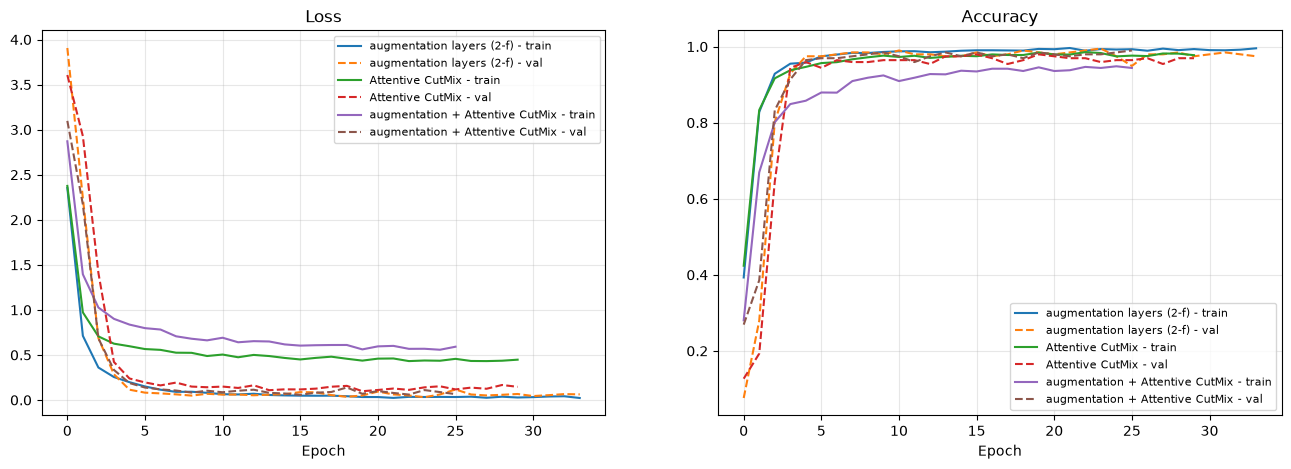

In [68]:
# Learning curves side by side: regular augmentation vs Attentive CutMix (vs both)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for label, h in [('augmentation layers (2-f)', histories_3[0]), ('Attentive CutMix', history_acm),
                 ('augmentation + Attentive CutMix', history_acm_aug)]:
    axes[0].plot(h.history['loss'], label=f'{label} - train')
    axes[0].plot(h.history['val_loss'], '--', label=f'{label} - val')
    axes[1].plot(h.history['accuracy'], label=f'{label} - train')
    axes[1].plot(h.history['val_accuracy'], '--', label=f'{label} - val')
axes[0].set_title('Loss'); axes[1].set_title('Accuracy')
for ax in axes:
    ax.set_xlabel('Epoch'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

### Results and discussion

| model (same network, same split) | test accuracy | mean per-class accuracy | classes with 0% |
|---|---|---|---|
| 2-c: original data | 0.970 | 0.923 | 2 |
| 2-e: oversampled | 0.980 | 0.958 | 1 |
| 2-f: oversampled + augmentation layers | 0.990 | 0.989 | 0 |
| **Bonus: oversampled + Attentive CutMix** | 0.980 | 0.964 | 1 |
| **Bonus: oversampled + augmentation + Attentive CutMix** | **0.995** | **0.997** | **0** |

**What we see**

* **Attentive CutMix alone** improves a little over plain oversampling (mean per-class accuracy 0.964 vs 0.958) but is **worse than the regular augmentation layers** (0.989). Pasting 6 patches does not change the geometry or lighting of the image, while rotation / zoom / brightness create exactly the kind of variation we have between real photos of traffic signs.
* **Attentive CutMix + regular augmentation** gave the best result of all models: only 1 mistake on the 197 test images and no class with 0% accuracy. The two methods are complementary: augmentation teaches invariance to viewing conditions, CutMix teaches the model to recognise a sign when part of it is covered and makes the predictions less over-confident.
* **Learning curves.** With Attentive CutMix the *training* loss stays high (~0.45–0.6) while the validation loss is low. This is expected and not underfitting: half of the training images have mixed labels like 88% / 12%, and the cross-entropy against such soft labels can never reach 0. The validation curves are as stable as with regular augmentation.
* **Limitations of the attention.** The attention comes from ResNet-50 trained on ImageNet, which was never trained on traffic signs. In the examples above it often focuses on the sign (symbols, red border), but sometimes on textured background such as bricks or corners of the image (first row). Then the pasted patches carry little information about class B, but the label still says 12% B – exactly the label noise the method tries to avoid. A feature extractor fine-tuned on traffic signs (e.g. our own trained CNN) would probably give better maps.
* **How reliable is this?** The test set has only 197 images, so one image is 0.5% of accuracy. The difference between the best models (0.990 vs 0.995) is **a single image**, and each model was trained only once with one random seed. To claim that Attentive CutMix really helps, the experiment would need several runs with different seeds (or cross-validation) and a larger test set. On this dataset the models are already close to 100%, so there is little room left for a regulariser to show its effect – the paper reports its gains on harder datasets (CIFAR-100, ImageNet).

**Conclusion:** Attentive CutMix is easy to add on top of the existing pipeline (one extra pass of a pretrained network to compute the attention maps, then cheap patch pasting), and combined with standard augmentation it gave the best model in this experiment. Used alone it was weaker than simple, well-chosen geometric and brightness augmentations.

<font color='red'> Please, keep in mind that we expect a lot from the bonus exercise solutions. In order to claim all points the solution must resemble a blog post with examples, figures, explanations, reasoning and nicely documented code.

# Comments (optional feedback to the course instructors)
Here, please, leave your comments regarding the homework, possibly answering the following questions:
* how much time did you send on this homework?
* was it too hard/easy for you?
* what would you suggest to add or remove?
* anything else you would like to tell us

Your comments:

# <font color='red'>  End of the homework. Please don't delete this cell.</font>